<a href="https://colab.research.google.com/github/alanam1/Dados-abertos-e-Python-no-monitoramento-ambiental-urbano/blob/main/analiseartigo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import glob
import pandas as pd

pasta = "/content/drive/MyDrive//Artigo_ERI-2026/dados_extraidos"
arquivos = sorted(glob.glob(pasta + "/*.csv"))
print(arquivos)

df = pd.concat((pd.read_csv(f) for f in arquivos), ignore_index=True)
print(df.shape)

['/content/drive/MyDrive//Artigo_ERI-2026/dados_extraidos/bdqueimadas_2016-01-01_2017-01-01.csv', '/content/drive/MyDrive//Artigo_ERI-2026/dados_extraidos/bdqueimadas_2017-01-02_2018-01-01.csv', '/content/drive/MyDrive//Artigo_ERI-2026/dados_extraidos/bdqueimadas_2018-01-02_2019-01-01.csv', '/content/drive/MyDrive//Artigo_ERI-2026/dados_extraidos/bdqueimadas_2019-01-02_2020-01-01.csv', '/content/drive/MyDrive//Artigo_ERI-2026/dados_extraidos/bdqueimadas_2020-01-02_2021-01-01.csv', '/content/drive/MyDrive//Artigo_ERI-2026/dados_extraidos/bdqueimadas_2021-01-02_2022-01-01.csv', '/content/drive/MyDrive//Artigo_ERI-2026/dados_extraidos/bdqueimadas_2022-01-02_2023-01-01.csv', '/content/drive/MyDrive//Artigo_ERI-2026/dados_extraidos/bdqueimadas_2023-01-02_2024-01-01.csv', '/content/drive/MyDrive//Artigo_ERI-2026/dados_extraidos/bdqueimadas_2024-01-02_2025-01-01.csv', '/content/drive/MyDrive//Artigo_ERI-2026/dados_extraidos/bdqueimadas_2025-01-02_2025-12-31.csv']
(290019, 12)


**Leitura das primeiras 5 linhas do arquivo de 2016 - verificação**

In [ ]:
with open(arquivos[0], encoding="utf-8", errors="replace") as f:
    for _ in range(5):
        print(repr(f.readline()))

'DataHora,Satelite,Pais,Estado,Municipio,Bioma,DiaSemChuva,Precipitacao,RiscoFogo,FRP,Latitude,Longitude\n'
'2016/01/01 16:33:00,AQUA_M-T,Brasil,MATO GROSSO,BOM JESUS DO ARAGUAIA,Amazônia,0,1.7,0.1,39.1,-12.108,-51.883\n'
'2016/01/01 16:33:00,AQUA_M-T,Brasil,MATO GROSSO,SÃO FÉLIX DO ARAGUAIA,Amazônia,0,5.6,0.1,43.9,-11.109,-52.563\n'
'2016/01/02 17:15:00,AQUA_M-T,Brasil,MATO GROSSO,CAMPINÁPOLIS,Cerrado,0,0.6,0.8,7.7,-14.321,-53.341\n'
'2016/01/02 17:15:00,AQUA_M-T,Brasil,MATO GROSSO,PLANALTO DA SERRA,Cerrado,2,0.6,0.7,13.9,-14.709,-54.399\n'


**Leitura dos 10 arquivos**

In [ ]:
df = pd.concat(
    (pd.read_csv(f, sep=",", encoding="utf-8") for f in arquivos),
    ignore_index=True,
)
print(df.shape)
print(df.columns.tolist())

(290019, 12)
['DataHora', 'Satelite', 'Pais', 'Estado', 'Municipio', 'Bioma', 'DiaSemChuva', 'Precipitacao', 'RiscoFogo', 'FRP', 'Latitude', 'Longitude']


**Filtro dos 3 municípios**

In [ ]:
import unicodedata

def norm(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return s.upper().strip()

alvo = {"CACERES": "Cáceres", "CUIABA": "Cuiabá", "ALTA FLORESTA": "Alta Floresta"}

print("Satélites no arquivo:", df["Satelite"].unique())

texto = df["DataHora"].astype(str).str.replace("\ufeff", "", regex=False).str.strip()
df["DataHora"] = pd.to_datetime(texto, format="mixed", errors="coerce")

print("Datas não reconhecidas:", df["DataHora"].isna().sum())
print(texto[df["DataHora"].isna()].head(10).tolist())

df = df[df["DataHora"].notna()].copy()
df["mun"] = df["Municipio"].map(norm).map(alvo)
df = df[df["mun"].notna()].copy()
df = df[df["Satelite"] == "AQUA_M-T"]
df["ano"] = df["DataHora"].dt.year
df["mes"] = df["DataHora"].dt.month
df = df[df["ano"].between(2016, 2025)].drop_duplicates()

print(df.shape)
print(df.groupby("mun").size())

Satélites no arquivo: ['AQUA_M-T']
Datas não reconhecidas: 0
[]
(11872, 15)
mun
Alta Floresta    1250
Cuiabá           1776
Cáceres          8846
dtype: int64


**Focos por ano e município**

In [ ]:
por_ano = df.groupby(["ano", "mun"]).size().unstack(fill_value=0)
por_ano["Total"] = por_ano.sum(axis=1)
print(por_ano)

mun   Alta Floresta  Cuiabá  Cáceres  Total
ano                                        
2016            113     103      179    395
2017            135     100      232    467
2018             98      98      144    340
2019             69     237      732   1038
2020            209     270     2755   3234
2021            132     127     1226   1485
2022             98      73      133    304
2023            114      99      514    727
2024            198     607     2836   3641
2025             84      62       95    241


**Cálculo por km^2 e por mês**

In [ ]:
area_km2 = {"Cáceres": 24499.922, "Cuiabá": 4327.22, "Alta Floresta": 8955.409}

anos = por_ano.drop(columns="Total")
por_ano_norm = anos / pd.Series(area_km2) * 100
print("Focos por 100 km²:")
print(por_ano_norm.round(1))

por_mes = df.groupby(["mes", "mun"]).size().unstack(fill_value=0)
print("\nFocos por mês (2016-2025 somados):")
print(por_mes)

resumo = df.groupby("mun").agg(
    total=("ano", "size"),
    mes_pico=("mes", lambda s: s.value_counts().idxmax()),
)
resumo["por_100km2"] = resumo["total"] / pd.Series(area_km2) * 100
print("\nResumo:")
print(resumo.round(1))

Focos por 100 km²:
      Alta Floresta  Cuiabá  Cáceres
ano                                 
2016            1.3     2.4      0.7
2017            1.5     2.3      0.9
2018            1.1     2.3      0.6
2019            0.8     5.5      3.0
2020            2.3     6.2     11.2
2021            1.5     2.9      5.0
2022            1.1     1.7      0.5
2023            1.3     2.3      2.1
2024            2.2    14.0     11.6
2025            0.9     1.4      0.4

Focos por mês (2016-2025 somados):
mun  Alta Floresta  Cuiabá  Cáceres
mes                                
1               15       3      183
2               20       3      114
3               27       6      120
4               14       4       99
5               83      15      184
6              198      39      245
7               82     265      312
8              101     623     1552
9              476     733     3594
10             148      62     1581
11              67      14      598
12              19       9      2

In [ ]:
print(df.groupby(["mun", "Bioma"]).size())

mun            Bioma   
Alta Floresta  Amazônia    1250
Cuiabá         Cerrado     1674
               Pantanal     102
Cáceres        Amazônia     533
               Cerrado      796
               Pantanal    7517
dtype: int64


In [ ]:
bio = df.groupby(["mun", "Bioma"]).size().unstack(fill_value=0)
bio_pct = bio.div(bio.sum(axis=1), axis=0) * 100
print(bio_pct.round(1))

Bioma          Amazônia  Cerrado  Pantanal
mun                                       
Alta Floresta     100.0      0.0       0.0
Cuiabá              0.0     94.3       5.7
Cáceres             6.0      9.0      85.0


**Gráficos em tons de cinza**

O modelo da SBC pede figuras em preto e branco ou cinza, então os estilos de linha e marcador é que diferenciam os municípios. Na Figura 3, foi usado percentual do total de cada município em vez de números absolutos, porque assim dá para comparar o formato da sazonalidade mesmo com totais muito diferentes.

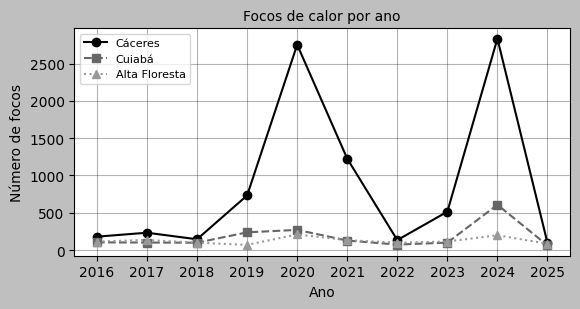

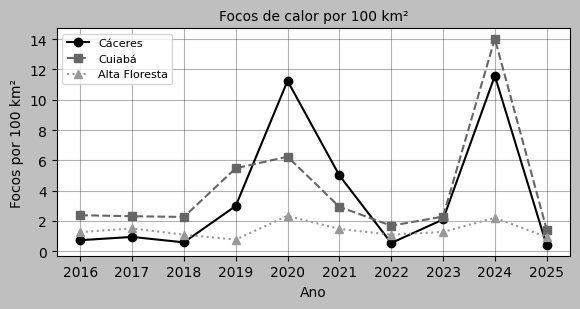

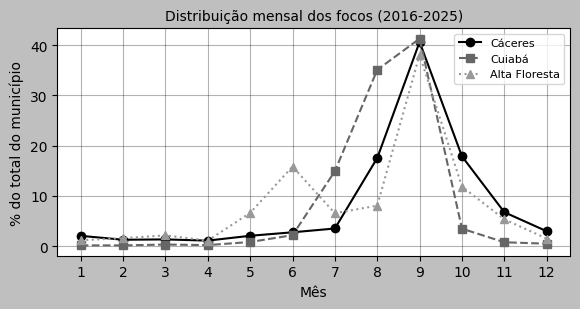

In [ ]:
import os
import matplotlib.pyplot as plt

plt.style.use("grayscale")
saida = "/content/drive/MyDrive/Artigo_ERI-2026/resultados/"
os.makedirs(saida, exist_ok=True)

estilos = {"Cáceres": ("o", "-"), "Cuiabá": ("s", "--"), "Alta Floresta": ("^", ":")}

def grafico(tab, titulo, ylabel, xlabel, arquivo, xticks=None):
    fig, ax = plt.subplots(figsize=(5.9, 3.2))
    for m in ["Cáceres", "Cuiabá", "Alta Floresta"]:
        mk, ls = estilos[m]
        ax.plot(tab.index, tab[m], marker=mk, linestyle=ls, label=m)
    ax.set_title(titulo, fontsize=10)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    if xticks is not None:
        ax.set_xticks(xticks)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(saida + arquivo, dpi=300)
    plt.show()

# Figura 1: focos por ano (valores absolutos)
grafico(anos, "Focos de calor por ano", "Número de focos", "Ano",
        "fig1_focos_por_ano.png", xticks=range(2016, 2026))

# Figura 2: focos por 100 km² por ano
grafico(por_ano_norm, "Focos de calor por 100 km²", "Focos por 100 km²", "Ano",
        "fig2_focos_por_100km2.png", xticks=range(2016, 2026))

# Figura 3: sazonalidade, em % do total de cada município
por_mes_pct = por_mes / por_mes.sum() * 100
grafico(por_mes_pct, "Distribuição mensal dos focos (2016-2025)", "% do total do município",
        "Mês", "fig3_sazonalidade.png", xticks=range(1, 13))

# Tabelas para o artigo
anos.to_csv(saida + "focos_por_ano.csv")
por_ano_norm.round(1).to_csv(saida + "focos_por_100km2.csv")
por_mes.to_csv(saida + "focos_por_mes.csv")
resumo.round(1).to_csv(saida + "resumo.csv")

In [ ]:
import sys, pandas, matplotlib
print(sys.version.split()[0], pandas.__version__, matplotlib.__version__)

3.13.16 2.2.3 3.10.0


Cálculo de fuso

In [ ]:
print(df["DataHora"].dt.hour.value_counts().sort_index())

DataHora
16     326
17    7837
18    3603
19     106
Name: count, dtype: int64


In [ ]:
hora = df["DataHora"].dt.hour + df["DataHora"].dt.minute / 60
solar = hora + df["Longitude"] / 15
print(solar.describe().round(2))

count    11872.00
mean        13.96
std          0.47
min         12.93
25%         13.61
50%         13.92
75%         14.29
max         15.48
dtype: float64
